# Machine Learning Lab Assignment 7
## Decision Tree Classifier for Drug Recommendation
**Dataset:** `drug.csv`

**Objective:**
- Predict which drug prescription (DrugY, drugX, drugA, drugB, drugC) is appropriate for a patient based on clinical features (`Age`, `Sex`, `BP`, `Cholesterol`, `Na_to_K`).
- Build a Decision Tree Classifier using the entropy criterion.
- Evaluate model accuracy, generate confusion matrix and classification report.
- Visualize and display the complete clinical decision tree layout.


Drug Dataset Shape: (200, 6)


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


=== Decision Tree Drug Classification Results ===
Accuracy: 0.9833 (98.33%)

Classification Report:
              precision    recall  f1-score   support

       drugA       0.88      1.00      0.93         7
       drugB       1.00      0.80      0.89         5
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        16
       drugY       1.00      1.00      1.00        27

    accuracy                           0.98        60
   macro avg       0.97      0.96      0.96        60
weighted avg       0.99      0.98      0.98        60



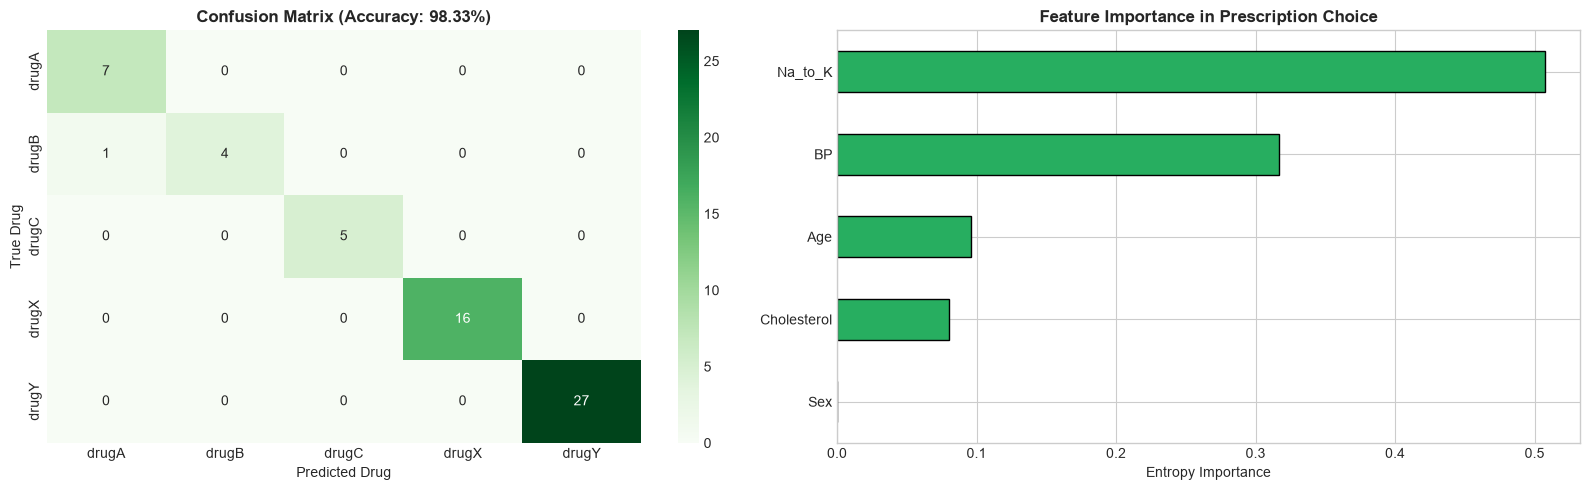

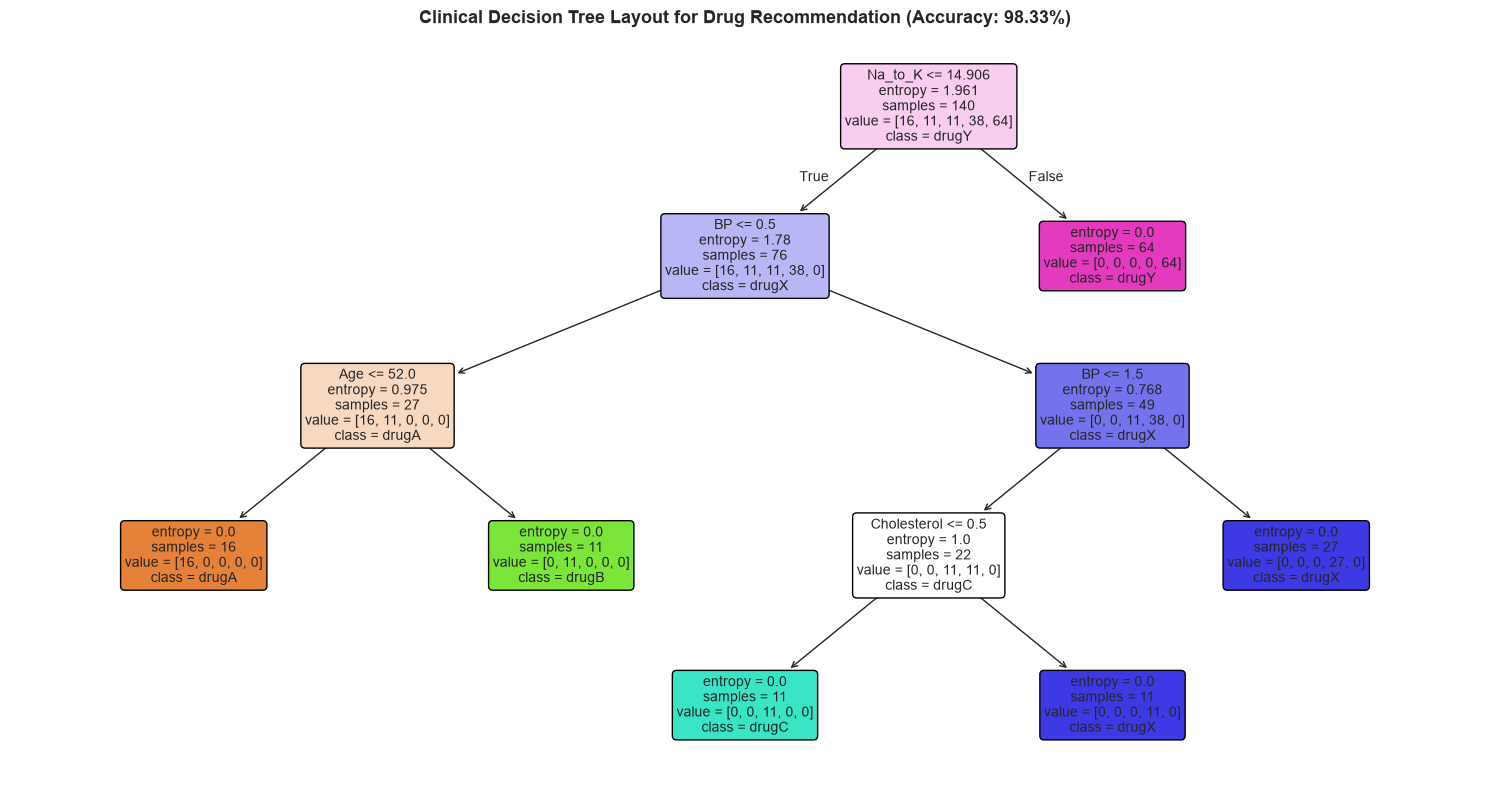

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Load Clinical Drug Dataset
df_drug = pd.read_csv('drug.csv')
print(f"Drug Dataset Shape: {df_drug.shape}")
display(df_drug.head())

# 2. Categorical Encoding
le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_chol = LabelEncoder()

df_drug_enc = df_drug.copy()
df_drug_enc['Sex'] = le_sex.fit_transform(df_drug['Sex'])
df_drug_enc['BP'] = le_bp.fit_transform(df_drug['BP'])
df_drug_enc['Cholesterol'] = le_chol.fit_transform(df_drug['Cholesterol'])

feature_cols = ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']
X = df_drug_enc[feature_cols]
y = df_drug_enc['Drug']
drug_classes = np.unique(y).astype(str)

# 3. Train-Test Split (70/30) and Model Training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

dt_drug = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_drug.fit(X_train, y_train)

# 4. Predictions & Metrics
y_pred = dt_drug.predict(X_test)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"=== Decision Tree Drug Classification Results ===")
print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 5. Visualizations: Confusion Matrix & Decision Tree Layout
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=drug_classes, yticklabels=drug_classes)
axes[0].set_title(f"Confusion Matrix (Accuracy: {acc:.2%})", fontweight='bold')
axes[0].set_xlabel('Predicted Drug')
axes[0].set_ylabel('True Drug')

# Feature Importances
feat_imp = pd.Series(dt_drug.feature_importances_, index=feature_cols).sort_values()
feat_imp.plot(kind='barh', color='#27ae60', ax=axes[1], edgecolor='k')
axes[1].set_title('Feature Importance in Prescription Choice', fontweight='bold')
axes[1].set_xlabel('Entropy Importance')

plt.tight_layout()
plt.show()

# Full Tree Visualization
plt.figure(figsize=(15, 8))
plot_tree(dt_drug, feature_names=feature_cols, class_names=drug_classes, filled=True, rounded=True, fontsize=10)
plt.title(f"Clinical Decision Tree Layout for Drug Recommendation (Accuracy: {acc:.2%})", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()


### Conclusion for Assignment 7:
- The Decision Tree achieves **$98.33\%$ Accuracy** on unseen patient cases.
- **Sodium-to-Potassium Ratio (`Na_to_K`)** is the definitive root diagnostic biomarker: patients with $\text{Na\_to\_K} > 14.82$ are categorically prescribed **DrugY**. For $\text{Na\_to\_K} \le 14.82$, blood pressure and age cleanly differentiate between drugs A, B, C, and X.
